# Value function supervised learning figures

This notebook is used to generate the different visualizations of the value function supervised learning. 
We have 2 types of plots: 
1. Loss curves
2. Value function estimation visualization 

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def make_vfunction_grids(root_truth=Path("./V_truth"), root_estimation=Path("./V_estimation")):
    """
    Automatically inspects ./V_estimation. Column 0 is $V^*$,
    and subsequent columns display each model's configuration read from its .toml file
    using a compact notation (hidden_dim -> H_d, n_hidden_layers -> N_d, omitting lr & input_dim).
    """
    environments = ["MountainCar", "Pendulum"]
    
    if not root_estimation.exists():
        print(f"[WARNING] El directorio {root_estimation} no existe.")
        return
    
    # Diccionario de traducción para abreviar hiperparámetros
    param_translation = {
        "hidden_dim": "H_d",
        "n_hidden_layers": "N_layers",
        "mlp_layers": "N_layers",
        "beta": "β"
    }
    
    # Parámetros a omitir por completo en los títulos
    ignored_params = {"lr", "input_dim", "environment", "elapsed_time", "output_dim"}

    for env_key in environments:
        model_names = []
        for model_path in root_estimation.iterdir():
            if model_path.is_dir() and (model_path / env_key).exists():
                model_names.append(model_path.name)
                
        if not model_names:
            continue
            
        model_names = sorted(model_names)

        if env_key == "MountainCar":
            ref_path = root_truth / "mountaincar_truth_reference.npz"
            if not ref_path.exists():
                continue
            ref_data = np.load(ref_path)
            x1_grid = ref_data["pgrid"]
            x2_grid = ref_data["vgrid"]
            vref = ref_data["vref"]
            xlabel, ylabel = "Position", "Velocity"
        elif env_key == "Pendulum":
            ref_path = root_truth / "pendulum_truth_reference.npz"
            if not ref_path.exists():
                continue
            ref_data = np.load(ref_path)
            x1_grid = ref_data["th_grid"]
            x2_grid = ref_data["v_grid"]
            vref = ref_data["vref"]
            xlabel, ylabel = "Theta", "Theta Dot"

        model_configs = {}
        max_configs = 1
        for model_name in model_names:
            estimation_dir = root_estimation / model_name / env_key
            est_files = list(estimation_dir.glob("V_est_config_*.npy"))
            
            config_indices = sorted(list(set([int(f.stem.split("_")[3]) for f in est_files])))
            model_configs[model_name] = config_indices
            if config_indices:
                max_configs = max(max_configs, len(config_indices))

        num_models = len(model_names)
        num_cols = 1 + max_configs
        num_rows = num_models

        fig, axes = plt.subplots(num_rows, num_cols, figsize=(4.5 * num_cols, 3.5 * num_rows), constrained_layout=True)
        
        if num_rows == 1 and num_cols == 1:
            axes = np.array([[axes]])
        elif num_rows == 1:
            axes = axes[np.newaxis, :]
        elif num_cols == 1:
            axes = axes[:, np.newaxis]

        extent = [x1_grid[0], x1_grid[-1], x2_grid[0], x2_grid[-1]]

        for row_idx, model_name in enumerate(model_names):
            # Columna 0: Verdad Terreno (solo título en la fila superior)
            axes[row_idx, 0].imshow(vref.T, origin="lower", extent=extent, aspect="auto", cmap="viridis")
            if row_idx == 0:
                axes[row_idx, 0].set_title("$V^*$", fontsize=10)
            axes[row_idx, 0].set_ylabel(f"{model_name}\n{ylabel}", fontsize=9)
            if row_idx == num_rows - 1:
                axes[row_idx, 0].set_xlabel(xlabel)

            config_indices = model_configs[model_name]
            estimation_dir = root_estimation / model_name / env_key

            for col_idx in range(max_configs):
                ax = axes[row_idx, col_idx + 1]
                
                if col_idx < len(config_indices):
                    cfg_idx = config_indices[col_idx]
                    est_file = estimation_dir / f"V_est_config_{cfg_idx}.npy"
                    toml_file = estimation_dir / f"V_est_config_{cfg_idx}.toml"
                    
                    if est_file.exists():
                        v_est_flat = np.load(est_file)
                        v_est = v_est_flat.reshape(vref.shape)
                        
                        ax.imshow(v_est.T, origin="lower", extent=extent, aspect="auto", cmap="viridis")
                        
                        title_str = f"Config {cfg_idx}"
                        if toml_file.exists():
                            try:
                                formatted_lines = []
                                with open(toml_file, "r", encoding="utf-8") as tf:
                                    for line in tf:
                                        line = line.strip()
                                        if not line or line.startswith("#"):
                                            continue
                                        if "=" in line:
                                            k, v = line.split("=", 1)
                                            k = k.strip()
                                            v = v.strip()
                                            # Omitir parámetros indeseados
                                            if k in ignored_params:
                                                continue
                                            # Traducir nombre de parámetro si existe
                                            key_mapped = param_translation.get(k, k)
                                            formatted_lines.append(f"{key_mapped}: {v}")
                                            
                                if formatted_lines:
                                    title_str = "\n".join(formatted_lines)
                            except Exception:
                                pass
                                
                        if row_idx == 0:
                            ax.set_title(title_str, fontsize=8)
                    else:
                        ax.text(0.5, 0.5, "Missing", ha="center", va="center", transform=ax.transAxes)
                    
                    ax.set_yticklabels([])
                    if row_idx == num_rows - 1:
                        ax.set_xlabel(xlabel)
                else:
                    ax.axis("off")

        fig.suptitle(f"Value Function Estimations Comparison - {env_key}", fontsize=14)
        plt.show()

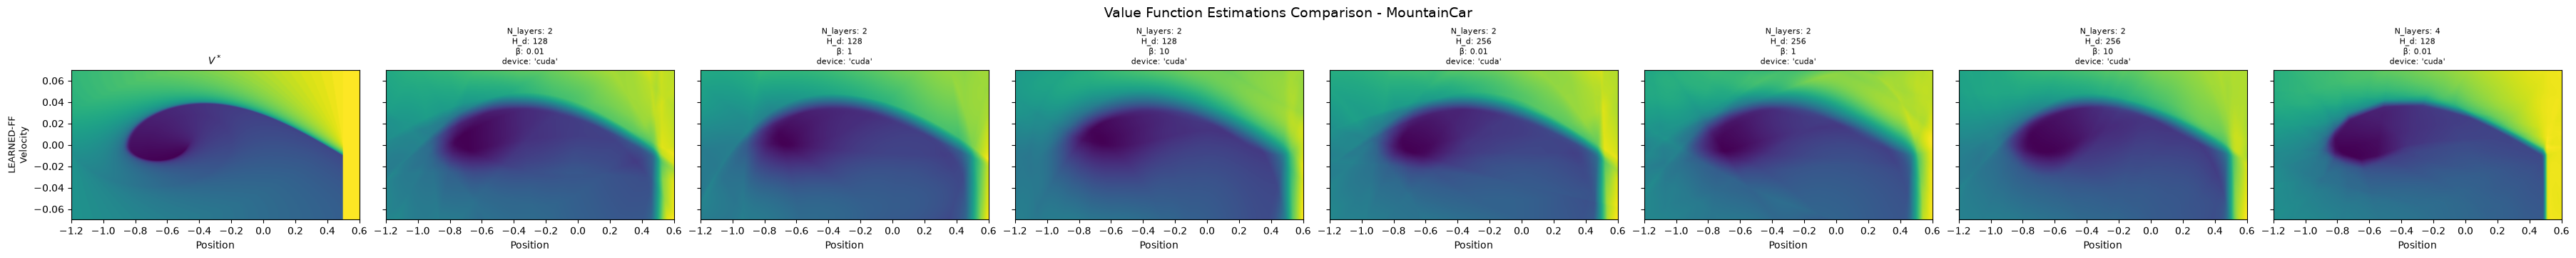

In [8]:
make_vfunction_grids()

In [4]:
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from pathlib import Path

def make_loss_curves_grid(env_key="MountainCar", results_dir=Path("./results")):
    """
    Generates a grid of loss curves:
    - Rows: Models
    - Columns: Number of MLP layers (N_d)
    - Subplots: Superimposed loss curves for different hidden dimensions (H_d) and beta (if applicable)
    """
    if not results_dir.exists():
        print(f"[WARNING] El directorio {results_dir} no existe.")
        return

    # 1. Descubrir modelos disponibles para este entorno
    model_names = [d.name for d in results_dir.iterdir() if d.is_dir() and (d / env_key).exists()]
    if not model_names:
        print(f"[INFO] No se encontraron resultados de loss para el entorno {env_key}.")
        return
    model_names = sorted(model_names)

    # 2. Recolectar datos y descubrir todos los valores posibles de N_d (mlp_layers)
    all_mlp_layers = set()
    model_data = {}

    for model_name in model_names:
        env_path = results_dir / model_name / env_key
        model_data[model_name] = []
        
        for parquet_file in env_path.glob("*.parquet"):
            table = pq.read_table(parquet_file)
            metadata = table.schema.metadata
            if metadata and b"hyperparameters" in metadata:
                hp = json.loads(metadata[b"hyperparameters"].decode("utf-8"))
                df = table.to_pandas()
                loss_values = df.iloc[0].values.astype(float)
                
                hidden_dim = hp.get("hidden_dim", hp.get("hidden_features", 64))
                mlp_layers = hp.get("mlp_layers", hp.get("n_hidden_layers", 1))
                beta = hp.get("beta", None) # Capturar beta si existe (para Lff, etc.)
                
                all_mlp_layers.add(mlp_layers)
                model_data[model_name].append({
                    "loss": loss_values,
                    "hidden_dim": hidden_dim,
                    "mlp_layers": mlp_layers,
                    "beta": beta
                })

    if not all_mlp_layers:
        print("[INFO] No se encontraron metadatos de hiperparámetros en los ficheros parquet.")
        return

    mlp_layers_list = sorted(list(all_mlp_layers))
    num_rows = len(model_names)
    num_cols = len(mlp_layers_list)

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(4.5 * num_cols, 3.5 * num_rows), constrained_layout=True, sharey=True)
    
    if num_rows == 1 and num_cols == 1:
        axes = np.array([[axes]])
    elif num_rows == 1:
        axes = axes[np.newaxis, :]
    elif num_cols == 1:
        axes = axes[:, np.newaxis]

    for row_idx, model_name in enumerate(model_names):
        configs = model_data[model_name]
        
        for col_idx, mlp_l in enumerate(mlp_layers_list):
            ax = axes[row_idx, col_idx]
            
            # Filtrar configuraciones que coincidan con este número de capas
            matching_configs = [c for c in configs if c["mlp_layers"] == mlp_l]
            
            if matching_configs:
                # Ordenar por hidden_dim (y beta si existe) para mantener consistencia
                matching_configs = sorted(matching_configs, key=lambda x: (x["hidden_dim"], x["beta"] if x["beta"] is not None else 0))
                
                for cfg in matching_configs:
                    h_d = cfg["hidden_dim"]
                    beta = cfg["beta"]
                    loss_curve = cfg["loss"]
                    epochs = np.arange(len(loss_curve))
                    
                    # Construir etiqueta de leyenda incluyendo beta si está presente
                    label_str = f"H_d: {h_d}"
                    if beta is not None:
                        label_str += f", β: {beta}"
                        
                    ax.plot(epochs, loss_curve, label=label_str)
                    
                ax.set_yscale("log")
                if row_idx == 0:
                    ax.set_title(f"N_d: {mlp_l}", fontsize=10)
                if col_idx == 0:
                    ax.set_ylabel(f"{model_name}\nLoss", fontsize=9)
                if row_idx == num_rows - 1:
                    ax.set_xlabel("Epochs", fontsize=9)
                ax.legend(fontsize=7, loc="upper right")
                ax.grid(True, which="both", ls="--", alpha=0.4)
            else:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", transform=ax.transAxes)
                if row_idx == 0:
                    ax.set_title(f"N_d: {mlp_l}", fontsize=10)
                if col_idx == 0:
                    ax.set_ylabel(model_name, fontsize=9)

    fig.suptitle(f"Training Loss Curves Comparison - {env_key}", fontsize=14)
    plt.show()

[INFO] No se encontraron resultados de loss para el entorno Pendulum.


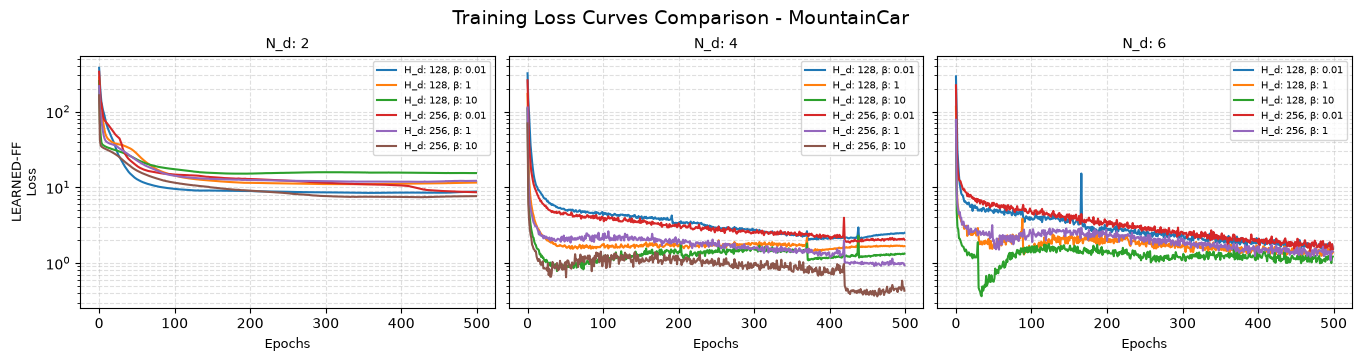

In [10]:
make_loss_curves_grid(env_key="Pendulum")
make_loss_curves_grid(env_key="MountainCar")